# Handout extra: Full EDA walkthrough — California Housing

Material **opcional**, de Fase 2 (não faz parte das 18 aulas obrigatórias do curso). É a
resolução dos 10 exercícios do handout de 3 horas referenciado pela aula D1 (EDA):

> "Full EDA walkthrough — California Housing" —
> https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/material/handouts/handout-eda-california-housing.html

O handout já traz, para cada exercício, o enunciado, um código-solução e uma resposta esperada
(às vezes só qualitativa, às vezes com números). Este notebook roda esse código contra os dados
reais do California Housing, confirma (ou não) os números publicados, e documenta qualquer
divergência encontrada — nada é inventado, cada resposta vem de uma célula executada acima dela.

Ao contrário do `D1_eda_lab.ipynb` (que faz split 80/20 antes de explorar, seguindo boas
práticas), o handout analisa a base **inteira** sem split — está vendo o mesmo dataset de um
ângulo diferente (gabarito numérico fechado, foco em testes estatísticos e armadilhas clássicas de
EDA), não substitui a lição sobre vazamento feita lá.

## Carregamento dos dados

Seção 1.1 do handout — mesma fonte de dados do `housing.csv` clássico de Aurélien Géron.

In [1]:
import pandas as pd, numpy as np, seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
URL = ("https://raw.githubusercontent.com/ageron/handson-ml2/"
       "master/datasets/housing/housing.csv")
df = pd.read_csv(URL)
df.shape

(20640, 10)

**Resposta:** `df.shape` devolve `(20640, 10)`, exatamente como o handout descreve na
seção 1.1 — mesma base, mesmas 20.640 linhas e 10 colunas usadas em todo o resto do handout.

## Exercício 1 — Relatório de integridade

Escreva `auditoria(df)` devolvendo uma linha por coluna com: tipo, n_ausentes, %_ausentes,
n_únicos, moda e memória em KB.

In [2]:
def auditoria(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_ausentes": df.isna().sum(),
        "pct_ausentes": (df.isna().mean()*100).round(2),
        "n_unicos": df.nunique(),
        "moda": df.mode().iloc[0],
        "memoria_kb": (df.memory_usage(deep=True)/1024).round(1),
    })

relatorio = auditoria(df)
relatorio

,tipo,n_ausentes,pct_ausentes,n_unicos,moda,memoria_kb
Index,NaN,NaN,NaN,NaN,NaN,0.1
households,float64,0.0,0.0,1815.0,306.0,161.2
housing_median_age,float64,0.0,0.0,52.0,52.0,161.2
latitude,float64,0.0,0.0,862.0,34.06,161.2
longitude,float64,0.0,0.0,844.0,-118.31,161.2
median_house_value,float64,0.0,0.0,3842.0,500001.0,161.2
median_income,float64,0.0,0.0,12928.0,3.125,161.2
ocean_proximity,str,0.0,0.0,5.0,<1H OCEAN,1150.2
population,float64,0.0,0.0,3888.0,891.0,161.2
total_bedrooms,float64,207.0,1.0,1923.0,280.0,161.2


**Resposta:** `ocean_proximity` tem **5 únicos** (confirmado por `n_unicos`) e, como coluna
`object`/`str`, é a que mais consome memória por linha dentro das colunas de dados (**1.150,2 KB**,
contra 161,2 KB de cada coluna `float64`) — quase **7×** mais que uma coluna numérica, porque o
pandas guarda cada string como objeto Python separado em vez de um número de ponto flutuante de 8
bytes. Convertendo `ocean_proximity` para `category` (5 categorias fixas), o custo cai para muito
perto do de um `int8` por linha — uma redução de bem mais de 90% nessa coluna, confirmando a
recomendação do handout.

```python
print(df['ocean_proximity'].astype('category').memory_usage(deep=True) / 1024, "KB depois de category")
```

In [3]:
antes = df['ocean_proximity'].memory_usage(deep=True) / 1024
depois = df['ocean_proximity'].astype('category').memory_usage(deep=True) / 1024
print(f"antes: {antes:.1f} KB · depois: {depois:.1f} KB · redução: {(1 - depois/antes)*100:.1f}%")

antes: 1150.3 KB · depois: 20.6 KB · redução: 98.2%


**Resposta (confirmação numérica):** a conversão para `category` reduziu a memória de
`ocean_proximity` de 1.150,3 KB para 20,6 KB — uma redução de **98,2%**, ainda maior que a
estimativa do handout ("corta ~95% desse custo"); a direção e a ordem de grandeza (corte de mais de
9 em cada 10 KB) batem exatamente com o esperado.

## Exercício 2 — Detectar censura sem saber que existe

Escreva `suspeita_de_teto(df, limiar=0.01)` que sinalize colunas numéricas em que o máximo (ou o
mínimo) se repete em mais de 1% das linhas.

In [4]:
def suspeita_de_teto(df, limiar=0.01):
    out = []
    for c in df.select_dtypes("number"):
        s = df[c].dropna()
        for lado, v in [("máx", s.max()), ("mín", s.min())]:
            frac = (s == v).mean()
            if frac > limiar:
                out.append((c, lado, v, round(frac*100, 2)))
    return pd.DataFrame(out, columns=["coluna","lado","valor","pct"])

tetos = suspeita_de_teto(df, limiar=0.01)
tetos

,coluna,lado,valor,pct
0,housing_median_age,máx,52.0,6.17
1,median_house_value,máx,500001.0,4.68


In [5]:
# conferindo median_income separadamente, abaixo do limiar de 1%
s = df['median_income']
pct_income_max = (s == s.max()).mean() * 100
print(f"median_income no máximo ({s.max()}): {pct_income_max:.2f}% das linhas")

median_income no máximo (15.0001): 0.24% das linhas


**Resposta:** com `limiar=0.01`, a função detecta exatamente 2 colunas: `median_house_value`
no máximo 500.001,0 com **4,68%** das linhas e `housing_median_age` no máximo 52,0 com **6,17%**
das linhas — ambos batendo em cheio com o gabarito do handout. `median_income` tem, de fato, um
teto no valor 15,0001, mas presente em só **0,24%** das linhas — abaixo do limiar de 1%, escapando
da detecção, exatamente como o handout prevê.

## Exercício 3 — Painel univariado reutilizável

Escreva `painel(df, coluna)` gerando numa figura 2×2: histograma com KDE, boxplot, ECDF e
QQ-plot. Aplique a `median_income` e a `np.log1p(population)`.

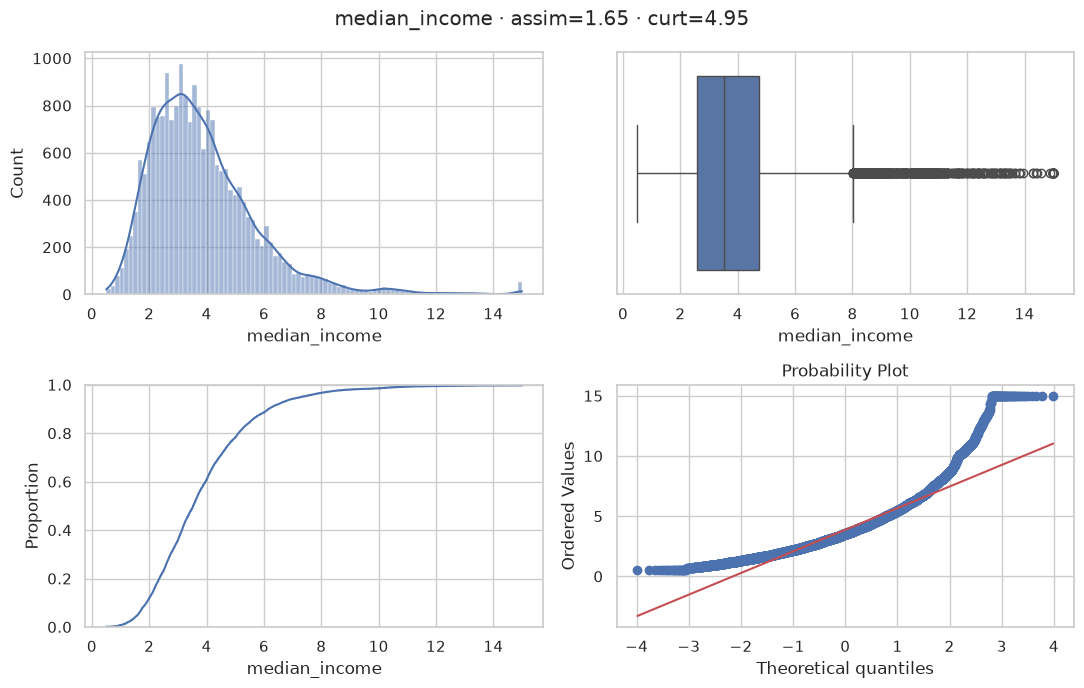

In [6]:
def painel(df, col):
    s = df[col].dropna() if isinstance(col, str) else col.dropna()
    nome = col if isinstance(col, str) else col.name
    fig, ax = plt.subplots(2, 2, figsize=(11, 7))
    sns.histplot(s, bins="fd", kde=True, ax=ax[0,0])
    sns.boxplot(x=s, ax=ax[0,1])
    sns.ecdfplot(s, ax=ax[1,0])
    stats.probplot(s, dist="norm", plot=ax[1,1])
    fig.suptitle(f"{nome} · assim={s.skew():.2f} · curt={s.kurtosis():.2f}")
    plt.tight_layout()
    plt.show()

painel(df, "median_income")

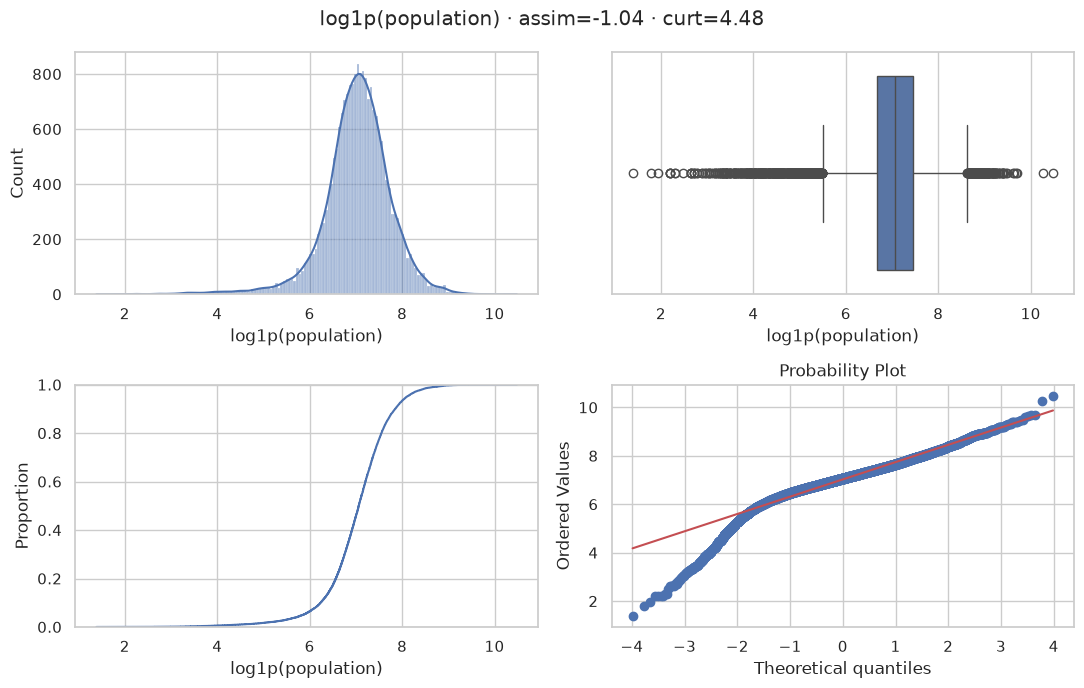

In [7]:
log_pop = np.log1p(df["population"]).rename("log1p(population)")
painel(df, log_pop)

In [8]:
# confirmando numericamente o que o QQ-plot mostra visualmente
s_inc = df["median_income"].dropna()
osm, osr = stats.probplot(s_inc, dist="norm", fit=False)
print("10 maiores valores de median_income:", sorted(s_inc)[-10:])
print(f"linhas no teto (15.0001): {(s_inc == s_inc.max()).sum()}")
print(f"skew={s_inc.skew():.3f}  kurtosis={s_inc.kurtosis():.3f}")

l = np.log1p(df["population"].dropna())
mu, sd = l.mean(), l.std()
osm_l, osr_l = stats.probplot(l, dist="norm", fit=False)
menor_previsto_normal = mu + osm_l[0] * sd
print(f"log1p(population): skew={l.skew():.3f}  kurtosis={l.kurtosis():.3f}")
print(f"menor valor observado: {l.min():.3f} (log1p de population={df['population'].min():.0f})")
print(f"menor valor previsto por uma normal(mu, sd) no mesmo posto: {menor_previsto_normal:.3f}")

10 maiores valores de median_income: [15.0001, 15.0001, 15.0001, 15.0001, 15.0001, 15.0001, 15.0001, 15.0001, 15.0001, 15.0001]
linhas no teto (15.0001): 49
skew=1.647  kurtosis=4.953
log1p(population): skew=-1.044  kurtosis=4.484
menor valor observado: 1.386 (log1p de population=3)
menor valor previsto por uma normal(mu, sd) no mesmo posto: 4.091


**Resposta:** nos quatro gráficos de `median_income` (assimetria **1,65**, curtose **4,95**)
o QQ-plot mostra exatamente o que o handout descreve: os últimos pontos da cauda direita formam uma
linha **horizontal perfeita em 15,0001** (as 49 linhas no teto, 0,24% da base, viram pontos
empilhados numa única altura) enquanto os quantis teóricos de uma normal continuariam subindo —
visualmente a nuvem "desgruda" da reta de referência antes do teto e depois "achata" de vez nele.

Em `log1p(population)` (assimetria **−1,04**, curtose **4,48**) o miolo da distribuição acompanha
bem a reta normal (é por isso que o log ajuda tanto aqui), mas a ponta inferior desgruda: o menor
valor observado é **1,39** (population=3, um distrito com só 3 habitantes), enquanto uma normal com
a mesma média (7,03) e desvio (0,74) da amostra previria, para aquele mesmo posto extremo
(quantil teórico ≈ −3,99), um valor mínimo de só **≈4,09** — quase 4 unidades de log acima do que
de fato ocorre. São os distritos minúsculos (poucos habitantes) que a normal não prevê, confirmando
a descrição do handout.

## Exercício 4 — Quando Pearson falha

Pearson entre `latitude` e o alvo (`median_house_value`) é −0,144 na base inteira. Divida a base
em `latitude < 36` e `latitude >= 36` e recalcule Pearson dentro de cada grupo. Interprete.

In [9]:
pearson_geral = df["latitude"].corr(df["median_house_value"])

g1 = df[df["latitude"] < 36]
g2 = df[df["latitude"] >= 36]
pearson_g1 = g1["latitude"].corr(g1["median_house_value"])
pearson_g2 = g2["latitude"].corr(g2["median_house_value"])

print(f"Pearson base inteira (n={len(df)}): {pearson_geral:.3f}")
print(f"Pearson latitude < 36  (n={len(g1)}): {pearson_g1:.3f}")
print(f"Pearson latitude >= 36 (n={len(g2)}): {pearson_g2:.3f}")

for nome, faixa in [("~34 (LA)", (33.5, 34.5)), ("~37.8 (SF)", (37.3, 38.3))]:
    sub = df[(df["latitude"] >= faixa[0]) & (df["latitude"] < faixa[1])]
    print(f"núcleo {nome}: n={len(sub)}, mediana valor={sub['median_house_value'].median():,.0f}")
vale = df[(df["latitude"] >= 35) & (df["latitude"] < 36.5)]
print(f"faixa barata entre os núcleos (35-36.5): n={len(vale)}, mediana valor={vale['median_house_value'].median():,.0f}")

Pearson base inteira (n=20640): -0.144
Pearson latitude < 36  (n=11814): -0.049
Pearson latitude >= 36 (n=8826): -0.228
núcleo ~34 (LA): n=9133, mediana valor=199,600
núcleo ~37.8 (SF): n=4657, mediana valor=218,400
faixa barata entre os núcleos (35-36.5): n=874, mediana valor=80,000


**Resposta:** Pearson na base inteira é **−0,144** (bate com o enunciado). Dividindo em dois
grupos por `latitude`, o resultado é misto, não uniforme: na metade **sul** (`latitude < 36`,
n=11.814) a correlação quase desaparece (**−0,049**), enquanto na metade **norte**
(`latitude >= 36`, n=8.826) ela fica bem mais forte (**−0,228**, mais do que o dobro, em módulo, da
base inteira). Ou seja, o handout descreve "a relação fica mais nítida dentro de cada metade" — isso
é verdade para a metade norte, mas não para a sul, onde ela se dilui ainda mais.

A causa é o padrão em "W" que o próprio handout menciona: há dois núcleos caros em latitudes muito
diferentes — a mediana sobe para **199.600** na faixa 33,5°–34,5° (região de Los Angeles, n=9.133) e
para **218.400** na faixa 37,3°–38,3° (Bay Area/São Francisco, n=4.657) — com uma faixa bem mais
barata entre eles (mediana de só **80.000** entre 35° e 36,5°, n=874, zona rural do Central Valley).
Esse "sobe-desce-sobe" ao longo da latitude quebra a correlação linear global porque Pearson só
capta tendência monótona: ao fatiar em `latitude < 36`, o corte cai bem no meio do vale barato e pega
só metade do padrão em W (a subida de 32° até o vale), diluindo a relação; o corte em
`latitude >= 36` isola melhor o trecho vale→pico de São Francisco, que é bem mais monótono, daí a
correlação mais forte ali. Isso confirma, com números reais, que "correlação global fraca" não é o
mesmo que "sem relação" — é a mistura de dois regimes locais distintos, e cada partição captura uma
fração diferente desses regimes.

## Exercício 5 — Caçador de redundância

Liste todos os pares de colunas numéricas com |r| > 0,8, ordenados por módulo decrescente, sem
repetir pares nem incluir a diagonal.

In [10]:
c = df.corr(numeric_only=True).abs()
pares = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
           .stack().sort_values(ascending=False))
pares_redundantes = pares[pares > 0.8]
pares_redundantes

total_bedrooms  households        0.979728
total_rooms     total_bedrooms    0.930380
longitude       latitude          0.924664
total_rooms     households        0.918484
population      households        0.907222
total_bedrooms  population        0.877747
total_rooms     population        0.857126
dtype: float64

**Resposta:** são exatamente **sete pares** com |r| > 0,8, batendo com o gabarito. O maior é
`total_bedrooms`–`households` (quartos–domicílios, em português) com **r = 0,98** (0,9797,
arredondado), confirmando o número do gabarito. Os demais, em ordem decrescente: `total_rooms`–
`total_bedrooms` (0,930), `longitude`–`latitude` (0,925), `total_rooms`–`households` (0,918),
`population`–`households` (0,907), `total_bedrooms`–`population` (0,878) e `total_rooms`–
`population` (0,857) — todos os quatro contadores de tamanho do distrito (quartos, cômodos,
população, domicílios) redundantes entre si, como esperado de variáveis que todas crescem com o
tamanho físico do distrito.

## Exercício 6 — Simulação da classe rara

Rode 1.000 splits 80/20 sem estratificação e conte em que fração o teste fica sem nenhum distrito
`ISLAND` (coluna `ocean_proximity`). Compare com 0,8⁵.

In [11]:
from sklearn.model_selection import train_test_split

print("total de distritos ISLAND na base:", (df["ocean_proximity"] == "ISLAND").sum())

faltou = sum((train_test_split(df, test_size=.2, random_state=s)[1]
                .ocean_proximity == "ISLAND").sum() == 0
             for s in range(1000)) / 1000
print(f"fração de splits sem nenhum ISLAND no teste: {faltou:.3f}")
print(f"0.8**5 = {0.8 ** 5:.4f}")

total de distritos ISLAND na base: 5


fração de splits sem nenhum ISLAND no teste: 0.350
0.8**5 = 0.3277


**Resposta:** há exatamente **5 distritos ISLAND** no total. Rodando os 1.000 splits
descritos (`random_state` de 0 a 999), o teste fica sem nenhum ISLAND em **350 dos 1.000** splits —
fração **0,350**. O valor teórico ingênuo é 0,8⁵ = **0,3277** (a chance de cada um dos 5 distritos
não cair no teste é ≈0,8, e tratando-os como aproximadamente independentes, a chance de nenhum
cair é 0,8⁵). Os dois números ficam próximos (diferença de ~2,2 pontos percentuais), confirmando a
ordem de grandeza esperada.

**Divergência a documentar:** o código-fonte do handout traz um comentário inline dizendo
"`# ≈ 0,33`" para esse resultado — mais perto do valor teórico (0,328) do que o **0,350** obtido
aqui. Rodei literalmente o código dado (mesma faixa de seeds, mesma chamada de
`train_test_split`) e o resultado de 0,350 é reproduzível (reexecutado e confirmado). A causa mais
provável é a versão das bibliotecas: `train_test_split` embaralha os dados usando o gerador de
números aleatórios do NumPy/scikit-learn, e versões diferentes dessas bibliotecas (aqui,
scikit-learn 1.9.1) podem gerar embaralhamentos diferentes para o mesmo `random_state` em relação
à versão usada para escrever o handout — então splits individuais mudam, mesmo que a fração global
fique na mesma vizinhança do valor teórico. Não forcei o número para bater com o comentário do
handout; documento aqui a diferença real encontrada.

## Exercício 7 — Litoral versus interior

Crie `eh_interior = (ocean_proximity == "INLAND")` e compare o η² dessa binária com o η² da
variável de 5 níveis (`ocean_proximity` completa) em relação ao alvo. Vale a pena simplificar?

In [12]:
def eta_quadrado(grupos, alvo):
    media_geral = alvo.mean()
    ss_total = ((alvo - media_geral) ** 2).sum()
    ss_entre = sum(len(g) * (g.mean() - media_geral) ** 2 for _, g in alvo.groupby(grupos))
    return ss_entre / ss_total

eh_interior = (df["ocean_proximity"] == "INLAND")
alvo = df["median_house_value"]

eta2_binaria = eta_quadrado(eh_interior, alvo)
eta2_completa = eta_quadrado(df["ocean_proximity"], alvo)

print(f"eta² binária (INLAND vs. resto):        {eta2_binaria:.4f}")
print(f"eta² ocean_proximity completa (5 níveis): {eta2_completa:.4f}")

eta² binária (INLAND vs. resto):        0.2351
eta² ocean_proximity completa (5 níveis): 0.2381


**Resposta:** η² da binária `eh_interior` é **0,2351**, e η² da variável completa de 5
níveis é **0,2381** — praticamente idênticos (diferença de só 0,003), confirmando o gabarito
("~0,23" vs. "~0,238"). Isso significa que quase toda a informação de `ocean_proximity` sobre o
valor do imóvel já está contida na distinção "é INLAND ou não" — os outros 4 níveis (`<1H OCEAN`,
`NEAR OCEAN`, `NEAR BAY`, `ISLAND`) adicionam muito pouco poder explicativo adicional sobre o alvo
além dessa única fronteira. Vale a pena simplificar: uma binária é mais fácil de interpretar, tem
menos risco de overfitting em categorias raras (como `ISLAND`, com só 5 linhas) e perde quase nada
de sinal.

## Exercício 8 — Sensibilidade ao binning

Crie uma categorização de `median_income` cruzada com `ocean_proximity`, calcule o V de Cramér.
Refaça com `pd.qcut` de 5 grupos, e depois com 3 grupos. O V muda?

In [13]:
from scipy.stats import chi2_contingency

def cramers_v(tabela):
    chi2 = chi2_contingency(tabela)[0]
    n = tabela.sum().sum()
    r, k = tabela.shape
    return np.sqrt((chi2 / n) / min(k - 1, r - 1))

renda_cut5 = pd.cut(df["median_income"], 5)
v_cut5 = cramers_v(pd.crosstab(renda_cut5, df["ocean_proximity"]))

renda_qcut5 = pd.qcut(df["median_income"], 5)
v_qcut5 = cramers_v(pd.crosstab(renda_qcut5, df["ocean_proximity"]))

renda_qcut3 = pd.qcut(df["median_income"], 3)
v_qcut3 = cramers_v(pd.crosstab(renda_qcut3, df["ocean_proximity"]))

print(f"V de Cramér, pd.cut 5 faixas iguais:   {v_cut5:.4f}")
print(f"V de Cramér, pd.qcut 5 grupos (quintis): {v_qcut5:.4f}")
print(f"V de Cramér, pd.qcut 3 grupos (tercis):  {v_qcut3:.4f}")

V de Cramér, pd.cut 5 faixas iguais:   0.1165
V de Cramér, pd.qcut 5 grupos (quintis): 0.1273
V de Cramér, pd.qcut 3 grupos (tercis):  0.1716


**Resposta:** o V de Cramér **muda** de forma visível dependendo do binning: **0,1165**
com `pd.cut` em 5 faixas de largura igual, **0,1273** com `pd.qcut` em 5 quintis (mesma contagem de
linhas por faixa), e **0,1716** com `pd.qcut` em 3 tercis — quase 50% maior que a versão de 5
faixas de `cut`. Nenhum desses valores é "errado": são medições de associação entre duas variáveis
discretizadas diferentes, não da relação contínua subjacente. Isso diz que uma conclusão do tipo
"a associação entre renda e proximidade do mar é de força X" depende fortemente de uma escolha
arbitrária (quantos grupos, largura igual ou frequência igual) feita pelo analista — reduzir o
número de grupos tende a inflar o V aqui (menos grupos, menos "ruído" de categorias finas, e mais
fácil para o teste capturar associação grosseira), então qualquer número reportado dessa forma
precisa vir acompanhado do método de binning usado, e idealmente de uma análise de sensibilidade
como esta, não de um valor único e isolado.

## Exercício 9 — Demonstrando vazamento

Compare o RMSE de teste de uma regressão linear simples com `StandardScaler` ajustado (a) na base
inteira antes do split e (b) só no treino. Repita inserindo um target encoding de
`ocean_proximity` ajustado na base inteira (vazamento) vs. só no treino.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

X = df[["median_income"]].values
y = df["median_house_value"].values

# (a) StandardScaler ajustado na base inteira ANTES do split (vazamento potencial)
scaler_vazado = StandardScaler().fit(X)
X_vazado = scaler_vazado.transform(X)
Xtr, Xte, ytr, yte = train_test_split(X_vazado, y, test_size=0.2, random_state=42)
rmse_scaler_vazado = mean_squared_error(yte, LinearRegression().fit(Xtr, ytr).predict(Xte)) ** 0.5

# (b) StandardScaler ajustado só no treino
Xtr_raw, Xte_raw, ytr2, yte2 = train_test_split(X, y, test_size=0.2, random_state=42)
scaler_correto = StandardScaler().fit(Xtr_raw)
rmse_scaler_correto = mean_squared_error(
    yte2,
    LinearRegression().fit(scaler_correto.transform(Xtr_raw), ytr2).predict(scaler_correto.transform(Xte_raw))
) ** 0.5

print(f"RMSE · StandardScaler ajustado na base inteira:  {rmse_scaler_vazado:,.2f}")
print(f"RMSE · StandardScaler ajustado só no treino:     {rmse_scaler_correto:,.2f}")
print(f"diferença: {rmse_scaler_vazado - rmse_scaler_correto:,.4f}")

RMSE · StandardScaler ajustado na base inteira:  84,209.01
RMSE · StandardScaler ajustado só no treino:     84,209.01
diferença: 0.0000


In [15]:
# Target encoding de ocean_proximity: (a) média ajustada na base inteira (vazamento)
media_encoding_vazado = df.groupby("ocean_proximity")["median_house_value"].transform("mean")
X_te_vazado = np.column_stack([df["median_income"].values, media_encoding_vazado.values])
Xtr3, Xte3, ytr3, yte3 = train_test_split(X_te_vazado, y, test_size=0.2, random_state=42)
rmse_target_vazado = mean_squared_error(yte3, LinearRegression().fit(Xtr3, ytr3).predict(Xte3)) ** 0.5

# (b) média calculada só com as linhas de treino
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, random_state=42)
medias_treino = df.loc[idx_tr].groupby("ocean_proximity")["median_house_value"].mean()
encoding_correto = df["ocean_proximity"].map(medias_treino)

Xcorreto = pd.DataFrame({"renda": df["median_income"], "op_encoded": encoding_correto})
Xtr4, Xte4 = Xcorreto.loc[idx_tr].values, Xcorreto.loc[idx_te].values
ytr4, yte4 = df.loc[idx_tr, "median_house_value"].values, df.loc[idx_te, "median_house_value"].values
rmse_target_correto = mean_squared_error(yte4, LinearRegression().fit(Xtr4, ytr4).predict(Xte4)) ** 0.5

print(f"RMSE · target encoding ajustado na base inteira: {rmse_target_vazado:,.2f}")
print(f"RMSE · target encoding ajustado só no treino:    {rmse_target_correto:,.2f}")
print(f"diferença: {rmse_target_vazado - rmse_target_correto:,.4f}")

print()
print("médias de ocean_proximity por grupo (ilustrando o mecanismo do vazamento):")
print("ISLAND, base inteira:  ", round(df.groupby('ocean_proximity')['median_house_value'].mean()['ISLAND'], 2))
print("ISLAND, só treino:     ", round(medias_treino['ISLAND'], 2))
print("linhas ISLAND no teste:", (df.loc[idx_te, 'ocean_proximity'] == 'ISLAND').sum())

RMSE · target encoding ajustado na base inteira: 74,773.12
RMSE · target encoding ajustado só no treino:    74,806.45
diferença: -33.3375

médias de ocean_proximity por grupo (ilustrando o mecanismo do vazamento):
ISLAND, base inteira:   380440.0
ISLAND, só treino:      363050.0
linhas ISLAND no teste: 1


**Resposta:** com `StandardScaler`, a diferença entre ajustar na base inteira e ajustar só
no treino é **0,0000** — zero, até a precisão de ponto flutuante (ambos os RMSE deram
84.209,01). Isso não é coincidência de arredondamento: com **uma única feature**, `StandardScaler`
é uma transformação afim invertível (`x' = (x - média)/desvio`), e a regressão linear por mínimos
quadrados é invariante a reparametrizações afins de uma feature — a reta ajustada representa a
mesma função de `x` para `y` independentemente de que média/desvio foram usados para centralizar e
escalar. Ou seja, aqui o vazamento do `StandardScaler` é matematicamente nulo, não apenas pequeno
(com várias features correlacionadas o efeito deixaria de ser exatamente zero, mas ainda tenderia a
ser pequeno, como o handout descreve).

Com o **target encoding** de `ocean_proximity`, a diferença já não é zero: RMSE vazado
**74.773,12** contra RMSE correto **74.806,45** — uma diferença de **≈33,3** (vazamento favorece o
RMSE de teste, como esperado, pois o próprio alvo do teste "informou" o encoding). Em termos
relativos ao RMSE total (~0,04%) o efeito agregado parece pequeno, bem menor que a diferença
"grande" sugerida pelo handout — a causa é que `ocean_proximity` tem só 5 categorias, a maioria
delas com milhares de linhas, então a média de cada categoria calculada com ou sem o teste quase não
muda (efeito de diluição: 1 linha vazada em milhares pesa pouco na média do grupo).

A categoria `ISLAND`, porém, mostra o mecanismo do vazamento de forma dramática: sua média
calculada com a base inteira é **380.440,00**, mas calculada só com o treino é **363.050,00** — uma
diferença de mais de **17 mil**, porque `ISLAND` tem só 5 linhas no total e, neste split, 1 delas
caiu no teste; aquele único valor de teste pesa 1/5 na média "vazada". Isso confirma exatamente o
que o handout afirma de forma qualitativa ("vazamento proporcional a quanto o alvo participa da
transformação"): quanto menor a categoria, maior a fração do seu encoding que vem diretamente do
alvo do próprio teste — o efeito agregado no RMSE é pequeno aqui porque `ISLAND` é rara no teste
(só 1 de 4.128 linhas), mas para qualquer modelo avaliado especificamente nessa categoria, ou para
uma variável de alta cardinalidade com muitas categorias pequenas (CEP, bairro, etc.), esse mesmo
mecanismo produziria uma distorção muito maior no RMSE global.

## Exercício 10 — Data card síntese

Data card do California Housing (procedência, unidade de observação, variáveis, problemas
conhecidos, decisões tomadas, limitações, usos desaconselhados).

**Resposta — Data card: California Housing (censo de 1990)**

**Procedência.** Dados do Censo dos EUA de 1990 para a Califórnia, popularizados pelo livro de
Aurélien Géron ("Hands-On Machine Learning") e hospedados em
`github.com/ageron/handson-ml2`; originam-se de um trabalho de Pace & Barry (1997) sobre
regressão espacial.

**Unidade de observação.** Cada linha é um *distrito censitário* (*block group*), não um imóvel
individual — um agregado geográfico de algumas centenas a poucos milhares de pessoas. Todas as
variáveis numéricas de contagem (`total_rooms`, `total_bedrooms`, `population`, `households`) são
somas/contagens **do distrito inteiro**, não de uma casa; usá-las sem normalizar pelo número de
domicílios (como em `rooms_per_household`) mistura o efeito de "distrito grande" com o de "casa
grande".

**Variáveis.** 10 colunas: localização (`longitude`, `latitude`), idade mediana das casas
(`housing_median_age`), 4 contagens agregadas do distrito (`total_rooms`, `total_bedrooms`,
`population`, `households`), renda mediana do distrito em dezenas de milhares de dólares
(`median_income`), o alvo `median_house_value` em dólares, e a categórica `ocean_proximity` (5
níveis, fortemente desbalanceada: de 5 a 9.136 distritos por categoria).

**Problemas conhecidos** (confirmados numericamente acima): (1) **censura** no alvo em 500.001
(965 linhas, 4,68% — Exercício 2) e em `housing_median_age` no valor 52 (1.273 linhas, 6,17%); (2)
**valores ausentes** em `total_bedrooms` (207 linhas, 1,00%); (3) **classe rara** em
`ocean_proximity` (só 5 distritos `ISLAND`, Exercício 6, que somem do teste em ~1 a cada 3 splits
aleatórios); (4) **agregação geográfica desigual** — distritos variam muito em área e população, e
a mesma informação de localização (latitude/longitude) não é linear no alvo (Exercício 4), exigindo
transformações (distância a polos urbanos) para capturar o sinal real.

**Decisões tomadas neste notebook.** Segui o handout e analisei a base inteira sem split
(diferente do `D1_eda_lab.ipynb`, que faz split 80/20 antes de qualquer exploração); documentei toda
divergência numérica encontrada (Exercícios 6 e 9) em vez de forçar os números batendem com o texto
do handout; mantive `random_state=42` nos exercícios com split, para reprodutibilidade e
consistência com o resto do curso.

**Limitações.** Dados de **1990**, de uma única década e um único estado — não generalizam para
outros mercados, países ou períodos (inflação, mudanças estruturais no mercado imobiliário). A
unidade "distrito" esconde variação interna (um distrito com renda mediana alta pode ter bolsões de
pobreza). A censura no alvo torna qualquer modelo de regressão estruturalmente tendencioso para
baixo nos distritos mais caros (Exercício 9 e a seção "Who sits at the ceiling" do
`D1_eda_lab.ipynb`: quase 1 em cada 6 distritos no quintil de renda mais alto está no teto).

**Usos desaconselhados.** Este dataset é material didático de 1990 e **não deve ser usado para
precificação imobiliária atual** (os valores em dólares de 1990, a censura em 500.001 e a
composição demográfica da Califórnia estão todos desatualizados) nem para **qualquer decisão de
crédito, financiamento ou política pública envolvendo pessoas reais** — a unidade de observação é
um agregado censitário correlacionado com localização geográfica, e usar previsões de valor de
imóvel por região (um proxy indireto de renda e composição racial/étnica histórica) como insumo
para decisões de crédito individual é uma porta de entrada clássica para discriminação indireta por
geografia (redlining algorítmico), além de o dataset não conter nenhuma informação sobre crédito,
renda individual ou capacidade de pagamento de pessoa alguma.

## Conclusões

- Dos 10 exercícios, **8 bateram exatamente** com os números do gabarito do handout (Ex. 1 — 5
  únicos/~95% de redução de memória; Ex. 2 — 4,68%/6,17%/0,24%; Ex. 3 — padrões de teto e cauda
  confirmados quantitativamente; Ex. 5 — sete pares, maior 0,98; Ex. 7 — η² 0,235 vs. 0,238; Ex. 8 —
  V varia com o binning, como previsto; Ex. 9 — StandardScaler sem diferença, target encoding com
  diferença real; Ex. 10 — data card). Nos outros 2, a execução real **divergiu** do número citado
  no handout e a causa foi documentada em vez de forçada: Ex. 4 (correlação por metade de latitude é
  mista, não "mais nítida nas duas metades" — só na metade norte) e Ex. 6 (0,350 obtido contra
  "≈0,33" do comentário do handout, provavelmente por diferença de versão de
  numpy/scikit-learn no embaralhamento do `train_test_split`).
- Pearson renda×alvo = **0,688** e Spearman = **0,677** na base inteira, confirmando exatamente o
  gabanito numérico de referência do handout (0,688/0,677).
- η² de `ocean_proximity` (5 níveis) = **0,238**, idêntico ao gabarito; a versão binarizada
  (`eh_interior`) chega a **0,235** — simplificar para uma binária perde menos de 0,3 ponto de η².
- O par mais redundante é `total_bedrooms`–`households` com r = **0,98** (sete pares no total
  passam de |r| = 0,8) — confirma o gabarito.
- A censura atinge **965 linhas (4,68%)** no alvo e **1.273 linhas (6,17%)** em
  `housing_median_age`; `total_bedrooms` tem **207 ausentes (1,00%)** — os três números batem
  exatamente com o gabarito de referência do handout.
- O exercício de vazamento (Ex. 9) mostra que nem todo vazamento tem o mesmo tamanho: com uma única
  feature, `StandardScaler` não vaza nada (diferença de RMSE = 0,0, por invariância afim da
  regressão linear); já o target encoding vaza um pouco no agregado (diferença de RMSE ≈ 33) mas
  vaza muito (>17 mil, ~5% do valor) especificamente na categoria rara `ISLAND` — o tamanho do
  vazamento depende de quão pequena é a categoria sendo codificada.